<a href="https://colab.research.google.com/github/Rageel-28/244107020136-Machine-Learning/blob/main/JS08/JS08_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS08 - Hierarchical Clustering
## Lab 3 - Eksperimen Hyperparameter HDBSCAN

Fokus praktikum ini hanya pada HDBSCAN: bagaimana hyperparameter mengubah hasil klasterisasi (jumlah *cluster*, pemisahan *noise*, dan adaptasi terhadap struktur data).

> **Catatan dataset:** halaman modul tidak menyebut dataset secara eksplisit, sehingga dipakai kembali data multiscale (kepadatan berbeda) dari Lab 2 agar hasilnya dapat dibandingkan langsung.

## Langkah 0 - Instalasi dan Import Library

In [1]:
# Paket hdbscan tidak termasuk scikit-learn. Pasang otomatis jika belum ada (Google Colab / lokal).
try:
    import hdbscan
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'hdbscan'])
    import hdbscan

print('hdbscan siap dipakai')

hdbscan siap dipakai


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score, davies_bouldin_score

## Langkah 1 - Data dan Fungsi Bantu

In [3]:
# Data yang sama dengan Lab 2 (kepadatan berbeda + 40 titik latar acak)
centers_ms = [[0, 0], [2.6, 2.6], [-5, 5]]
X_blob, _ = make_blobs(n_samples=[300, 300, 300], centers=centers_ms,
                       cluster_std=[0.2, 0.35, 1.8], random_state=7)
rng = np.random.default_rng(3)
X = np.vstack([X_blob, rng.uniform(-9, 10, size=(40, 2))])


def plot_clusters(X, labels, title='', ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    palette = sns.color_palette('deep', max(int(labels.max()) + 1, 1))
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(X[m, 0], X[m, 1], c='black', s=15, label='noise')
        else:
            ax.scatter(X[m, 0], X[m, 1], color=palette[lab], s=20, label=f'cluster {lab}')
    ax.set_title(title, fontsize=10)
    return ax


def ringkas(labels):
    n_cl = len(set(labels)) - (1 if -1 in labels else 0)
    return n_cl, int((labels == -1).sum())

## Langkah 2 - Eksperimen 1: Mengubah `min_cluster_size`

`min_cluster_size` adalah jumlah minimum titik agar suatu kelompok dianggap sebagai *cluster*. Nilai kecil menghasilkan banyak *cluster* kecil; nilai besar menggabungkan atau membuang kelompok kecil sebagai *noise*. Nilai yang dicoba: 3, 5, dan 25.

min_cluster_size= 3 -> 4 cluster, noise = 25
min_cluster_size= 5 -> 4 cluster, noise = 41
min_cluster_size=25 -> 3 cluster, noise = 34


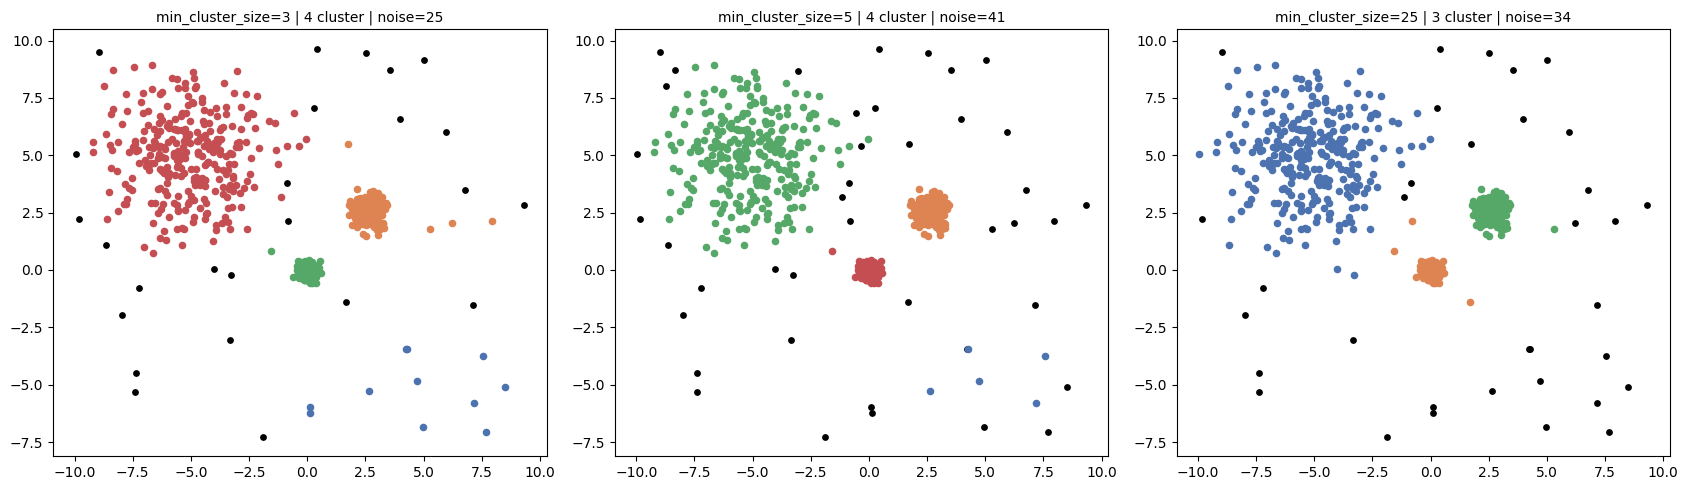

In [4]:
import hdbscan

hasil_eksperimen = {}   # nama eksperimen -> label
nilai_mcs = [3, 5, 25]

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, mcs in zip(ax, nilai_mcs):
    lab = hdbscan.HDBSCAN(min_cluster_size=mcs).fit_predict(X)
    n_cl, n_noise = ringkas(lab)
    plot_clusters(X, lab, f'min_cluster_size={mcs} | {n_cl} cluster | noise={n_noise}', a)
    hasil_eksperimen[f'mcs={mcs}'] = lab
    print(f'min_cluster_size={mcs:>2} -> {n_cl} cluster, noise = {n_noise}')
plt.tight_layout()
plt.show()

## Langkah 3 - Eksperimen 2: Mengubah `min_samples`

`min_samples` mengatur seberapa **konservatif** algoritma terhadap *noise*: makin besar, makin banyak titik di area kurang padat yang dianggap *noise*. Di sini `min_cluster_size` dibuat tetap **20**. Nilai yang dicoba: 3, 5, dan 25.

min_samples= 3 -> 3 cluster, noise = 36
min_samples= 5 -> 3 cluster, noise = 46
min_samples=25 -> 3 cluster, noise = 34


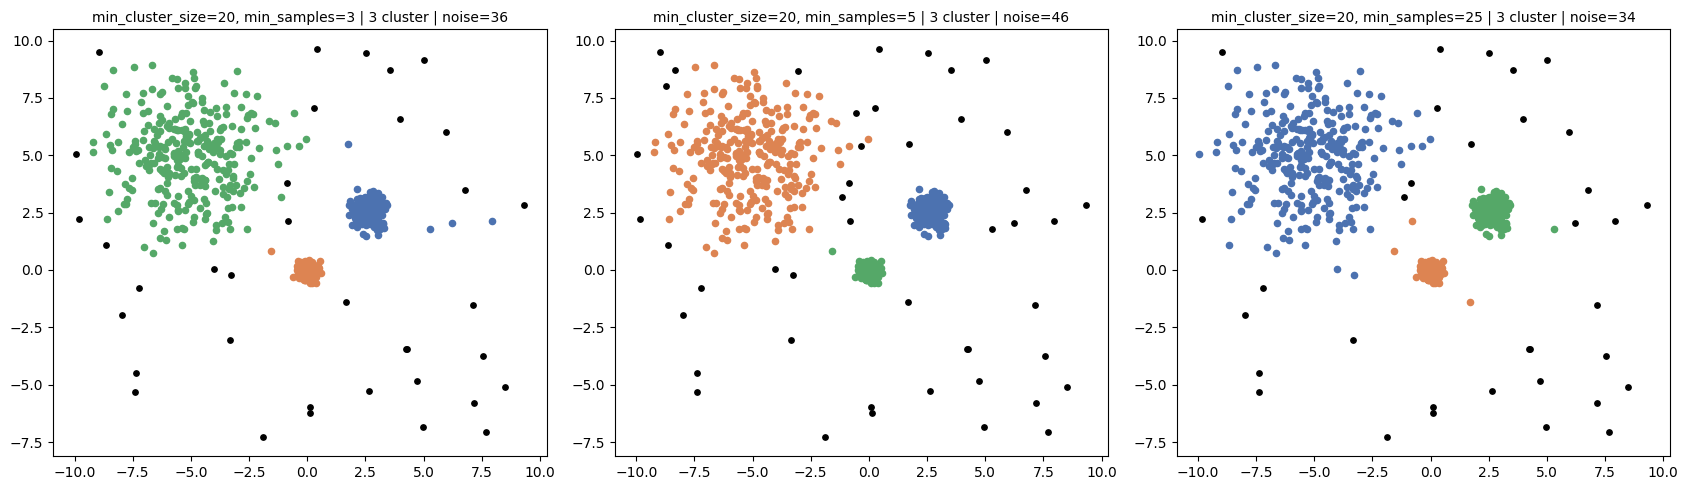

In [5]:
nilai_ms = [3, 5, 25]

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, ms in zip(ax, nilai_ms):
    lab = hdbscan.HDBSCAN(min_cluster_size=20, min_samples=ms).fit_predict(X)
    n_cl, n_noise = ringkas(lab)
    plot_clusters(X, lab, f'min_cluster_size=20, min_samples={ms} | {n_cl} cluster | noise={n_noise}', a)
    hasil_eksperimen[f'ms={ms}'] = lab
    print(f'min_samples={ms:>2} -> {n_cl} cluster, noise = {n_noise}')
plt.tight_layout()
plt.show()

## Langkah 4 - Eksperimen 3: Ekstraksi Klaster ala DBSCAN dari Pohon HDBSCAN (`cut_distance`)

Pohon hierarki HDBSCAN dapat "dipotong" pada jarak tertentu (`cut_distance`) sehingga menghasilkan *cluster* seperti DBSCAN dengan `eps` tersebut, tetapi **tanpa melatih ulang model**. Nilai yang dicoba: 0.1, 0.5, dan 1.0.

cut_distance=0.1 -> 2 cluster, noise = 493
cut_distance=0.5 -> 3 cluster, noise = 185
cut_distance=1.0 -> 3 cluster, noise = 63


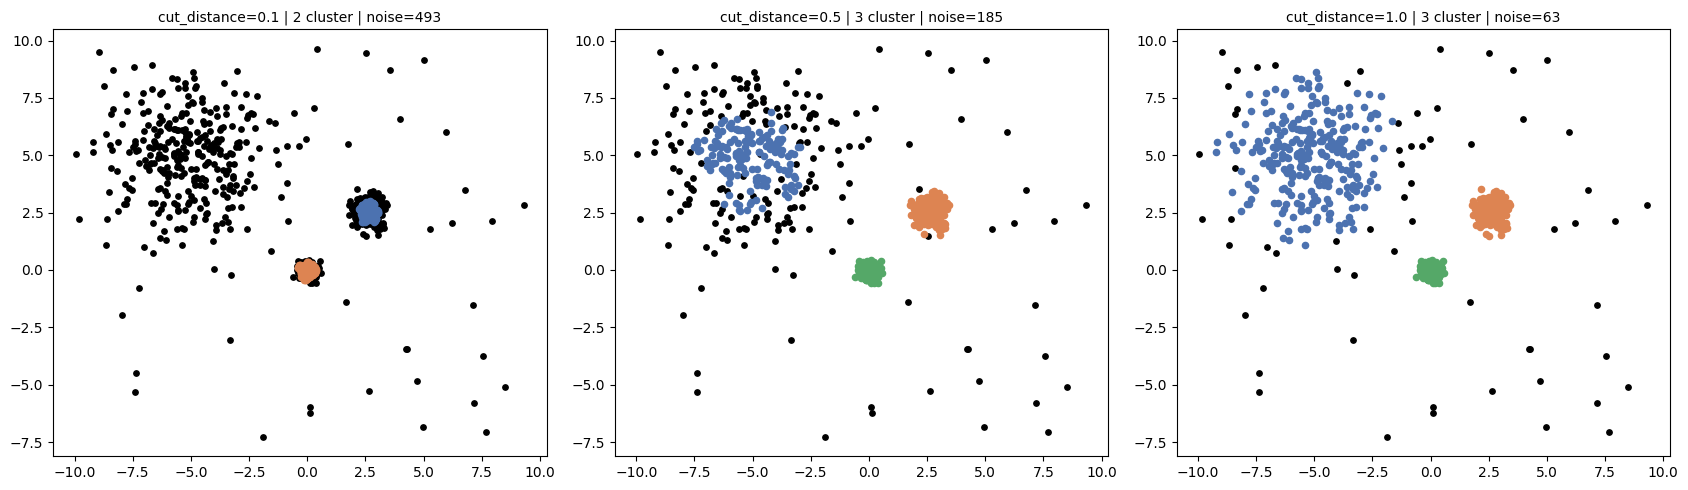

In [6]:
model_dasar = hdbscan.HDBSCAN(min_cluster_size=20, min_samples=5).fit(X)

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, cd in zip(ax, [0.1, 0.5, 1.0]):
    lab = model_dasar.single_linkage_tree_.get_clusters(cut_distance=cd, min_cluster_size=20)
    n_cl, n_noise = ringkas(lab)
    plot_clusters(X, lab, f'cut_distance={cd} | {n_cl} cluster | noise={n_noise}', a)
    hasil_eksperimen[f'cut={cd}'] = lab
    print(f'cut_distance={cd} -> {n_cl} cluster, noise = {n_noise}')
plt.tight_layout()
plt.show()

## Langkah 5 - Evaluasi dengan Silhouette Score

Nilai mendekati **+1** berarti *cluster* terpisah dengan baik; nilai **negatif** berarti banyak titik salah/campur *cluster*. Evaluasi hanya dapat dihitung bila terdapat ≥ 2 *cluster*. Titik *noise* **dikeluarkan** dari perhitungan karena bukan anggota *cluster* mana pun.

In [7]:
def evaluasi(X, labels):
    mask = labels != -1
    if len(set(labels[mask])) < 2:
        return np.nan, np.nan
    return silhouette_score(X[mask], labels[mask]), davies_bouldin_score(X[mask], labels[mask])


baris = []
for nama, lab in hasil_eksperimen.items():
    sil, dbi = evaluasi(X, lab)
    n_cl, n_noise = ringkas(lab)
    baris.append({'Eksperimen': nama, 'Jumlah cluster': n_cl, 'Noise': n_noise,
                  'Silhouette': sil, 'Davies-Bouldin': dbi})

tabel = pd.DataFrame(baris)
tabel

,Eksperimen,Jumlah cluster,Noise,Silhouette,Davies-Bouldin
0,mcs=3,4,25,0.756829,0.397859
1,mcs=5,4,41,0.770109,0.318684
2,mcs=25,3,34,0.759526,0.335170
3,ms=3,3,36,0.760791,0.330720
4,ms=5,3,46,0.771303,0.322446
5,ms=25,3,34,0.759526,0.335170
6,cut=0.1,2,493,0.906830,0.138234
7,cut=0.5,3,185,0.842677,0.223021
8,cut=1.0,3,63,0.785019,0.305502


## Langkah 6 - Evaluasi dengan Davies-Bouldin Index (DBI)

DBI mengukur rasio sebaran di dalam *cluster* terhadap jarak antar *cluster*: **makin kecil makin baik** (*cluster* padat dan terpisah). Nilai besar menandakan *cluster* saling tumpang tindih. DBI sudah dihitung pada tabel di atas.

## Langkah 7 - Visualisasi Skor Evaluasi

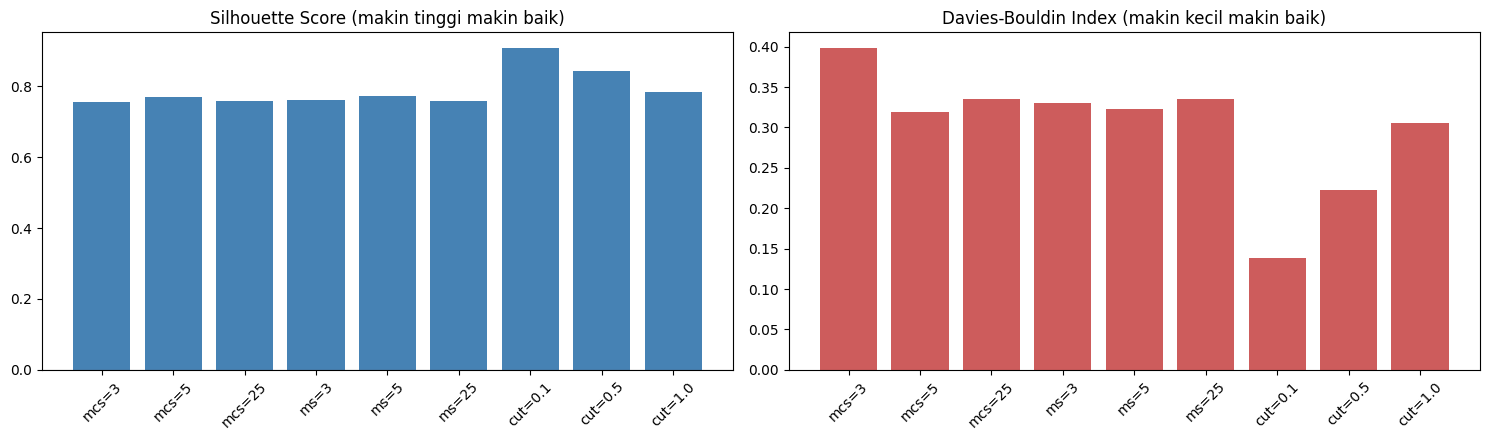

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

ax[0].bar(tabel['Eksperimen'], tabel['Silhouette'], color='steelblue')
ax[0].set_title('Silhouette Score (makin tinggi makin baik)')
ax[0].tick_params(axis='x', rotation=45)
ax[0].axhline(0, color='gray', linewidth=0.8)

ax[1].bar(tabel['Eksperimen'], tabel['Davies-Bouldin'], color='indianred')
ax[1].set_title('Davies-Bouldin Index (makin kecil makin baik)')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Analisis

Hasil di bawah berlaku untuk data dan `random_state` pada notebook ini (jumlah dapat sedikit berbeda jika data diganti):

- **`min_cluster_size`** (3, 5, 25): nilai 3 menghasilkan **4 *cluster*** (satu *cluster* tambahan berukuran kecil), sedangkan nilai 5 dan 25 menghasilkan **3 *cluster*** yang sesuai struktur data. Nilai yang terlalu kecil cenderung memecah data menjadi kelompok-kelompok kecil.
- **`min_samples`** (3, 5, 25 dengan `min_cluster_size=20`): jumlah *cluster* tetap 3, dan jumlah *noise* hanya berubah sedikit serta **tidak naik secara monoton** (ikuti angka pada keluaran Langkah 3). Secara teori `min_samples` yang lebih besar membuat model lebih konservatif terhadap *noise*, tetapi pada data ini efeknya kecil sehingga tidak boleh dilebih-lebihkan.
- **`cut_distance`** (0.1, 0.5, 1.0): efeknya paling jelas. Pemotongan sangat rendah (0.1) hanya menyisakan *cluster* yang sangat padat dan membuang sebagian besar data sebagai *noise*; makin besar `cut_distance`, jumlah *noise* makin turun dan ketiga *cluster* terbentuk (mirip DBSCAN dengan `eps` yang makin besar).
- **Membaca skor evaluasi**: *silhouette* dan DBI di sini dihitung **tanpa titik *noise***. Karena itu skor yang tinggi dapat menyesatkan bila banyak titik dibuang (misalnya `cut=0.5` memiliki skor tinggi tetapi membuang jauh lebih banyak titik daripada `cut=1.0`). Jika suatu eksperimen hanya menyisakan 1 *cluster* atau kurang, skornya tidak dapat dihitung (NaN). Baca skor bersama kolom jumlah *cluster* dan *noise*.